In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("homeprices_banglore.csv")
df.sample(5)

,area,bedrooms,price
16,1180,3,48.00
13,1100,2,40.00
0,1056,2,39.07
17,1540,3,60.00
15,1175,2,42.00


In [3]:
from sklearn.preprocessing import MinMaxScaler
sc_x = MinMaxScaler()
sc_y = MinMaxScaler() # we take two because for prediction at end we use reverse transform
scaled_x = sc_x.fit_transform(df.drop(["price"],axis=1))
scaled_y = sc_y.fit_transform(df[["price"]])

In [4]:
scaled_x[:5]

array([[0.08827586, 0.25      ],
       [0.62068966, 0.75      ],
       [0.22068966, 0.5       ],
       [0.24862069, 0.5       ],
       [0.13793103, 0.25      ]])

In [5]:
scaled_y[:5]

array([[0.05237037],
       [0.65185185],
       [0.22222222],
       [0.31851852],
       [0.14074074]])

##### prices = w1\*area + w2*bedrooms + bias

In [6]:
np.random.seed(42)

In [8]:
np.random.permutation(5)

array([1, 4, 2, 0, 3])

In [20]:
def mini_batch_gradient_descent(X,y_true,epochs=100,lr=0.01,batch_size = 5):
    m,n = X.shape
    # initialize weights
    w = np.ones(n)
    b = 0
    if batch_size>m: # In this case mini batch becomes same as batch gradient descent
        batch_size = m
    num_batches = m//batch_size
    cost_list = []
    epoch_list = []
    # no of epochs
    for i in range(epochs):
        random_idx = np.random.permutation(m)
        temp_X = X[random_idx]
        temp_y = y_true[random_idx]
        # lopps for batchs. [1,3,6,2,4,5],2 batchs with size 3: 1st batch [1,3,6], 2nd batch [2,4,5]
        for j in range(0,m,batch_size):
            # batch samples
            Xj = temp_X[j:j+batch_size]
            yj = temp_y[j:j+batch_size]
            # forward pass
            y_pred = np.dot(Xj,w)+b
            # calculate loss
            cost = np.mean(np.square(yj-y_pred)) # (1/batch_size)*np.sum((yj-y_pred)**2) #MSE
            # claculate gradient
            dw = -(2/len(Xj))*np.dot(Xj.T,(yj-y_pred))
            db = -(2/len(Xj))*np.sum(yj-y_pred)
            # update weights
            w = w - lr * dw
            b = b- lr*db
        if i%10==0:
            cost_list.append(cost)
            epoch_list.append(i)
            # print(f"Epoch: {i}, cost: {cost:.3f}")
    return w,b,cost,cost_list, epoch_list
            

In [21]:
w, b, cost, cost_list, epoch_list = mini_batch_gradient_descent(scaled_x,scaled_y.reshape(-1,),epochs=120,batch_size=5)

In [22]:
w, b, cost

(array([0.71001625, 0.67804898]),
 np.float64(-0.23351478888513147),
 np.float64(0.007329763386274185))

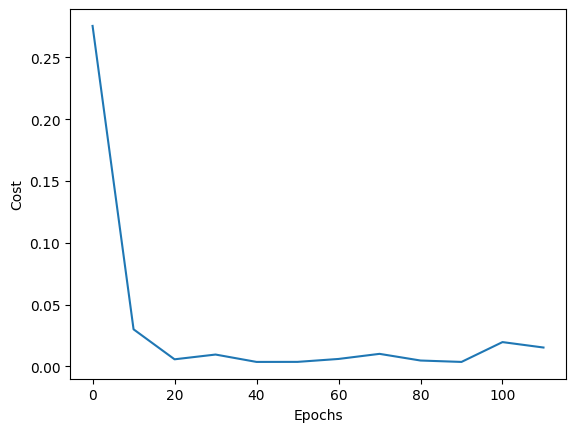

In [23]:
plt.plot(epoch_list,cost_list)
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.show()

In [28]:
def predict(area,bedrooms,w,b):
    scaled_X = sc_x.transform([[area,bedrooms]])[0]
    y_pred = np.dot(scaled_X,w) +b
    return sc_y.inverse_transform([[y_pred]])[0][0]

In [29]:
predict(2600,4,w,b)

/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


np.float64(128.6224275033816)

In [30]:
predict(1000,2,w,b)

/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


np.float64(29.970152633998822)